### The question it should answer
1. Are all values valid number? No NaN or inf
2. Are the values plausible? Ranges and units make sense: temperature around 200-300K, humidity around 0-1, pressure > 0, wind speed >= 0.
3. What do the distributions look like? For example, precipitation is very skewed with many dry days. This informs the type of transformations we might want to apply to the data.

In [6]:
import os
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
xr.set_options(use_bottleneck=False)
# Disable bottleneck: xarray uses bottleneck to speed up 
# some operations (rolling etc.). But, it accumulates sums
# in float32, which gave wrong std value off by 1.9K.

import matplotlib.pyplot as plt

In [2]:
# Data directory
DATADIR = Path('../data/lite/')


for path in sorted(DATADIR.glob('*.nc')):
    print(path.name)

NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_forcings_all.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1850_1931.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_hist_train_1932_2014.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_test_forcings_ssp245.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp126.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp370.nc
NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp585.nc


In [3]:
filename = "NorESM2-MM_r1i1p1f1_with_forcing_subsampled_16_train_ssp126.nc"

ds = xr.open_dataset(DATADIR / filename, chunks="auto")

In [4]:
tas = ds['tas']

p01 = tas.quantile(0.01).values
p50 = tas.quantile(0.50).values
p99 = tas.quantile(0.99).values

print("Mininum :", tas.min().values)
print("Maxinum :", tas.max().values)
print("Mean    :", tas.mean().values)
print("Std     :", tas.std().values)


print("1st percentile:", p01)
print("50st percentile:", p50)
print("99st percentile:", p99)

Mininum : 201.67216
Maxinum : 310.6852
Mean    : 278.92538
Std     : 21.091805
1st percentile: 219.1815020751953
50st percentile: 284.4742736816406
99st percentile: 303.3890380859375


In [6]:
tasmax = ds["tasmax"]
tasmin = ds["tasmin"]

violations = (tasmin > tas) | (tas > tasmax)

n_violations = violations.sum().values

print("Total comparisons:", tas.size)
print("Temperature ordering violations:", n_violations)
print("Violation percentage:", 100 * n_violations / tas.size)

Total comparisons: 6780024
Temperature ordering violations: 0
Violation percentage: 0.0


The mean is not an area-weighted global mean. The data cover very cold and warm regions of Earth. The mean evaluation assigns equal weight to every grid cell. This is not a optimal representation because a sample near the pole will correspond a much smaller area than a sample near the equator. 

In [9]:
def summary_stats(ds, variables):
      """Pooled min/max/mean/std/percentiles for each variable in `variables` present in `ds`."""
      rows = []
      for name in variables:
          if name not in ds:          # skip variables this file doesn't have
              continue
          da = ds[name]
          rows.append({
              "variable": name,
              "units": da.attrs.get("units", "unknown"),
              "min": da.min().values,
              "max": da.max().values,
              "mean": da.mean().values,
              "std": da.std().values,
              "p01": da.quantile(0.01).values,
              "median": da.quantile(0.50).values,
              "p99": da.quantile(0.99).values,
          })
      return pd.DataFrame(rows).set_index("variable")

In [10]:
targets = [
    "tas",
    "tasmax",
    "tasmin",
    "pr",
    "huss",
    "psl",
    "sfcWind"
]

summary_stats(ds, targets)

,units,min,max,mean,std,p01,median,p99
variable,,,,,,,,
tas,K,201.67216,310.6852,278.92538,21.091805,219.1815020751953,284.4742736816406,303.3890380859375
tasmax,K,203.78348,317.94257,280.79977,20.972507,220.9189910888672,286.2705535888672,308.4694519042969
tasmin,K,199.40544,304.93488,277.1325,21.351446,217.37689910888673,282.3153991699219,301.6164245605469
pr,kg m-2 s-1,0.0,0.0005532745,2.7655595e-05,3.36428e-05,6.335357198850033e-08,1.5473174244107213e-05,0.00015603488922351957
huss,1,2.7452108e-06,0.023157215,0.007792974,0.0062843584,2.741039825195912e-05,0.006104913540184498,0.02033622147515416
psl,Pa,92663.7,106767.234,100868.43,1361.6165,96925.23796875,101156.875,103359.5859375
sfcWind,m s-1,0.5555345,21.830137,6.2746286,2.530327,2.065204985141754,5.931021690368652,13.461047925949085


In [11]:
forcings = ['CO2_LBC', 'N2O_LBC', 'CH4_LBC',
            'CFC11eq_LBC', 'CF2CL2_LBC', 'BC_AX',
            'BC_N', 'SO2', 'SO4_PR', 'OM_NI']

summary_stats(ds, forcings)

,units,min,max,mean,std,p01,median,p99
variable,,,,,,,,
CO2_LBC,unknown,0.00039994894,0.00047399916,0.0004554925,1.9481497e-05,0.00040264179988298566,0.00046189034765120596,0.0004739987853099592
N2O_LBC,unknown,3.2817982e-07,3.5391304e-07,3.439978e-07,6.6383152e-09,3.2894153889628797e-07,3.451633716622382e-07,3.5373274300809496e-07
CH4_LBC,unknown,1.0564094e-06,1.8883894e-06,1.4601884e-06,2.7632427e-07,1.0604894328025693e-06,1.4288443708210252e-06,1.8874629915899278e-06
CFC11eq_LBC,unknown,3.1590963e-10,8.891047e-10,5.71642e-10,2.0704799e-10,3.17919596204419e-10,5.08643654972829e-10,8.885574331873869e-10
CF2CL2_LBC,unknown,2.1832101e-10,5.1801935e-10,3.4906344e-10,8.8093643e-11,2.202368336312599e-10,3.3843347568840443e-10,5.151000459502342e-10
BC_AX,molecules cm-2 s-1,0.0,4975202897.889926,45917306.67009033,148189319.26621583,0.0,2982459.526187969,633611054.8738589
BC_N,molecules cm-2 s-1,0.0,44776824166.33191,413255742.0159631,1333703815.5355303,0.0,26842134.558560416,5702499235.270285
SO2,molecules cm-2 s-1,0.0,31168432425.744286,296809185.18876237,902440443.0473591,0.0,45262709.39530054,4254464287.7149625
SO4_PR,molecules cm-2 s-1,0.0,799190570.3821359,7610491.862065971,23139498.336625084,0.0,1160582.2865823791,109088827.31973968


### Full data

In [4]:
# Full data
DATADIR = Path('/scratch3/workspace/riteshbachhar_uri_edu-climx/data/full/')

for path in sorted(DATADIR.glob('*.nc')):
    print(path.name)

NorESM2-MM_r1i1p1f1_with_forcing_hist_train_1850_1931.nc
NorESM2-MM_r1i1p1f1_with_forcing_hist_train_1932_2014.nc
NorESM2-MM_r1i1p1f1_with_forcing_test_forcings_ssp245.nc
NorESM2-MM_r1i1p1f1_with_forcing_train_ssp126.nc
NorESM2-MM_r1i1p1f1_with_forcing_train_ssp370.nc
NorESM2-MM_r1i1p1f1_with_forcing_train_ssp585.nc


In [5]:
filename = "NorESM2-MM_r1i1p1f1_with_forcing_train_ssp126.nc"

ds = xr.open_dataset(DATADIR / filename, chunks="auto")

In [7]:
tas = ds['tas']

# Build the lazy computations
# quantiles = tas.quantile([0.01, 0.50, 0.99])

stats = xr.Dataset({
    "min": tas.min(),
    "max": tas.max(),
    "mean": tas.mean(),
    "std": tas.std(),
    # "quantiles": quantiles,
})

# Execute the computations together
stats = stats.compute()

print("Minimum :", stats["min"].item())
print("Maximum :", stats["max"].item())
print("Mean    :", stats["mean"].item())
print("Std     :", stats["std"].item())

# print("1st percentile :", stats["quantiles"].sel(quantile=0.01).item())
# print("50th percentile:", stats["quantiles"].sel(quantile=0.50).item())
# print("99th percentile:", stats["quantiles"].sel(quantile=0.99).item())

Minimum : 194.85035705566406
Maximum : 320.8027648925781
Mean    : 278.9250183105469
Std     : 21.77775764465332


Full data is divided to `n_blocks` of `block_size` consecutive days each. 

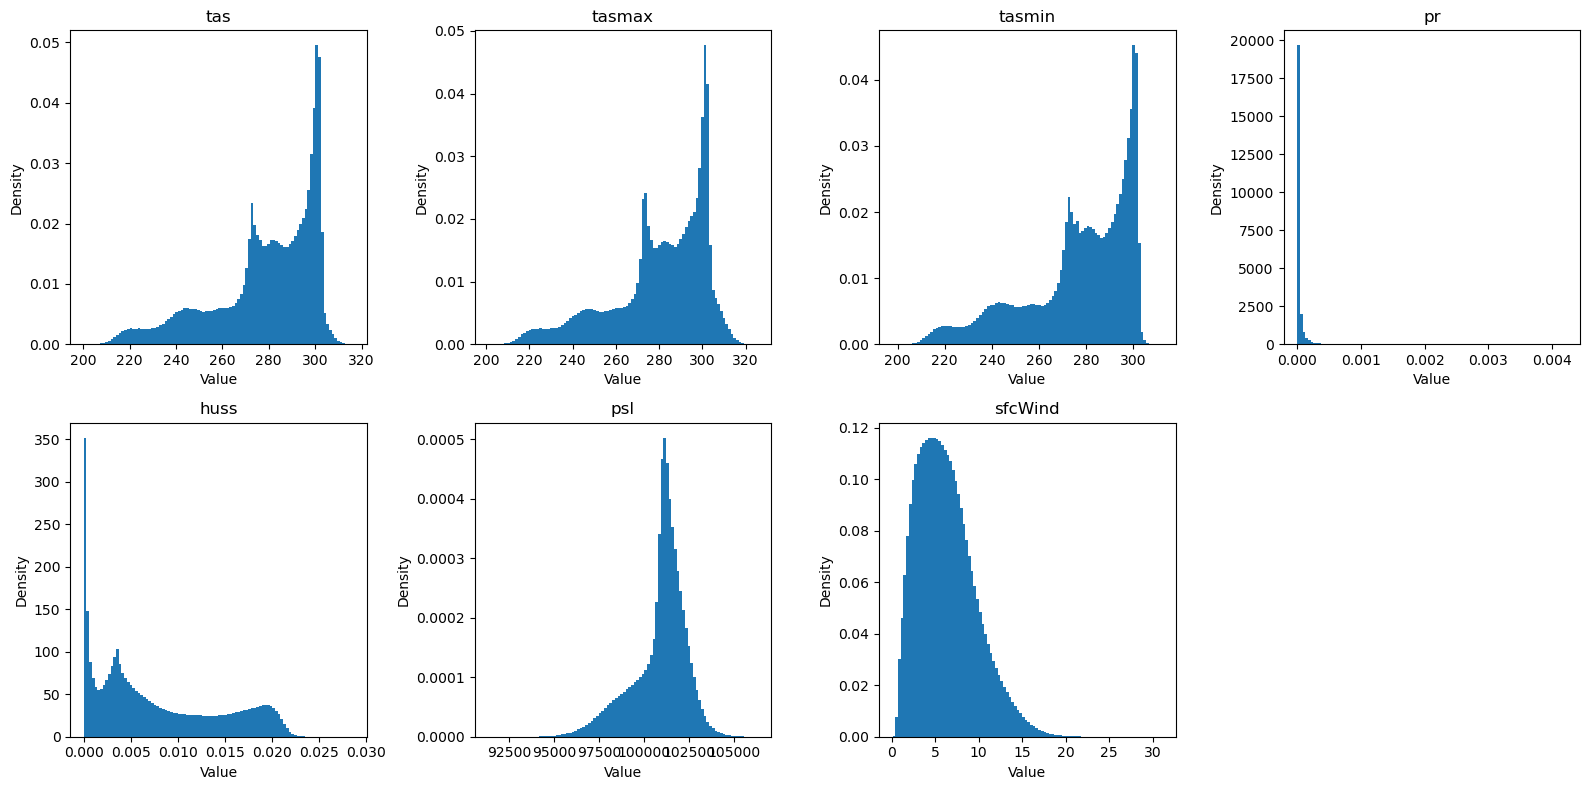

In [ ]:
variables = [
    "tas", "tasmax", "tasmin",
    "pr", "huss", "psl", "sfcWind"
]

n_blocks = 10
block_size = 100

n_time = ds.sizes["time"]

starts = np.linspace(
    0, n_time - block_size, n_blocks, dtype=int
)

blocks = [
    ds[variables].isel(time=slice(start, start + block_size)) for start in starts
]

ds_sample = xr.concat(blocks, dim="time").compute()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, var in zip(axes.flat, variables):
    values = ds_sample[var].values.ravel()
    values = values[np.isfinite(values)]

    ax.hist(values, bins=100, density=True)
    ax.set_title(var)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

for ax in axes.flat[len(variables):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

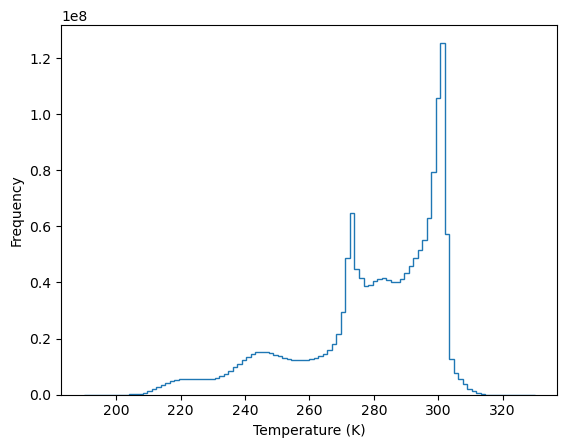

In [28]:
import dask.array as da

tas = ds["tas"]

bins = np.linspace(190, 330, 101)

# Build a lazy histogram computation
counts, edges = da.histogram(
    tas.data,
    bins=bins
)

# Execute using Dask
counts = counts.compute()

plt.stairs(counts, edges)
plt.xlabel("Temperature (K)")
plt.ylabel("Frequency")
plt.show()